# STA 556 — Homework 4: Simulation & Resampling

**Name:** Benjamin Owusu Acquah  
**Seed:** 556

In this notebook I use simulation and resampling to answer statistical questions computationally. In Parts 1 and 2 I estimate a Binomial event probability by Monte Carlo simulation and study how the estimate behaves as the number of simulations grows. In Part 3 I bootstrap the difference in means of two groups from a small real dataset (Student's (1908) sleep data), and in Part 4 I test the same difference with a permutation test. I create a single RNG object once and use it for every random step, so the notebook is reproducible from top to bottom.

**Setup.** This cell installs any missing packages into the Python that runs this notebook. It does nothing if they are already installed.

In [1]:
import importlib.util
import subprocess
import sys

required = ["numpy", "pandas", "matplotlib", "scipy"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("Missing before install:", missing)

Missing before install: []


## Simulation design

I define every design choice once as a named constant instead of hard-coding it where it is used.

| Constant | Value | Meaning |
|---|---|---|
| `SEED` | 556 | seed for the single RNG object |
| `N_TRIALS`, `P_SUCCESS` | 30, 0.25 | model: $X \sim \text{Binomial}(30, 0.25)$ |
| `THRESHOLD` | 12 | event of interest: $X \ge 12$ |
| `N_SIM` | chosen in Part 1 | number of Monte Carlo simulations |
| `N_BOOT` | 10,000 | number of bootstrap replicates (Part 3) |
| `N_PERM` | 10,000 | number of permutations (Part 4) |

I write the resampling mechanisms as functions that take `rng` as an explicit argument, and I pass the statistic in as a function. This keeps the resampling mechanism separate from the statistic being evaluated.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

SEED = 556
N_TRIALS = 30
P_SUCCESS = 0.25
THRESHOLD = 12
N_BOOT = 10_000
N_PERM = 10_000

rng = np.random.default_rng(SEED)
print("Seed used:", SEED)

Seed used: 556


In [3]:
def simulate_indicator(n_trials, p, threshold, n_sim, rng):
    draws = rng.binomial(n_trials, p, size=n_sim)
    return (draws >= threshold).astype(float)


def difference_in_means(x, y):
    return np.mean(x) - np.mean(y)


def bootstrap_two_sample(x, y, statistic, n_boot, rng):
    results = np.empty(n_boot)
    for b in range(n_boot):
        x_star = rng.choice(x, size=len(x), replace=True)
        y_star = rng.choice(y, size=len(y), replace=True)
        results[b] = statistic(x_star, y_star)
    return results


def permutation_null(x, y, statistic, n_perm, rng):
    pooled = np.concatenate([x, y])
    n_x = len(x)
    results = np.empty(n_perm)
    for b in range(n_perm):
        shuffled = rng.permutation(pooled)
        results[b] = statistic(shuffled[:n_x], shuffled[n_x:])
    return results

## Part 1 — Monte Carlo probability

**Target.** For $X \sim \text{Binomial}(n=30,\ p=0.25)$ I estimate $\theta = P(X \ge 12)$. The mean of $X$ is 7.5 and its SD is about 2.37, so $X \ge 12$ is an upper-tail event about two standard deviations above the mean. It is a fairly small probability, which makes Monte Carlo error easy to see.

**Method (indicator averaging).** Let $I_m = \mathbf 1\{X_m \ge 12\}$. Since $E[I] = P(X \ge 12)$, the Monte Carlo estimate is
$$\hat\theta = \frac1M \sum_{m=1}^{M} I_m .$$
The theoretical value is $1 - F(11) = \sum_{x=12}^{30}\binom{30}{x}0.25^{x}0.75^{30-x}$, which I compute with `scipy.stats.binom.sf` for comparison. I estimate the Monte Carlo standard error as `g.std(ddof=1) / sqrt(len(g))`, where `g` holds the indicators.

**Choosing the simulation size.** I did not want to pick a simulation size just because it sounds large, so I chose it from a precision target. Each indicator is Bernoulli($\theta$), so $\text{SE}(\hat\theta) = \sqrt{\theta(1-\theta)/M}$. If I want $\text{SE} \le 0.0025$, I need $M \ge \theta(1-\theta)/0.0025^2$. I do not know $\theta$ exactly in advance, so I first run a small pilot of 1,000 simulations to get a rough value, and then solve for $M$.

In [4]:
PILOT_N = 1_000
TARGET_SE = 0.0025

pilot_p = simulate_indicator(N_TRIALS, P_SUCCESS, THRESHOLD, PILOT_N, rng).mean()
required_n = int(np.ceil(pilot_p * (1 - pilot_p) / TARGET_SE ** 2))
N_SIM = 10_000

print(f"Pilot estimate (N = {PILOT_N:,})          : {pilot_p:.4f}")
print(f"Target Monte Carlo SE                 : {TARGET_SE}")
print(f"Simulations needed for that SE        : {required_n:,}")
print(f"Chosen simulation size N_SIM          : {N_SIM:,}")
print(f"Expected MC SE at N_SIM (pilot-based) : {np.sqrt(pilot_p * (1 - pilot_p) / N_SIM):.5f}")

Pilot estimate (N = 1,000)          : 0.0650
Target Monte Carlo SE                 : 0.0025
Simulations needed for that SE        : 9,724
Chosen simulation size N_SIM          : 10,000
Expected MC SE at N_SIM (pilot-based) : 0.00247


**Why I chose $M = 10{,}000$.**
- A standard error of 0.0025 means the 95% interval has half-width of about 0.005. On a probability near 0.05, that is about 10% of its size, which is precise enough to compare the estimate with the theoretical value and to see whether they agree.
- The pilot gave a requirement of about 9,700 simulations, so I rounded up to the next round number, 10,000. The pilot estimate itself is noisy (it uses only 1,000 draws), so I treat the 9,700 as a rough guide and keep a little margin rather than using it exactly.
- Computation is cheap: the draws are vectorized, so 10,000 simulations take a fraction of a second. Going much larger would cost little in time, but it would not change the conclusion, and halving the SE would need four times as many simulations.
- Part 2 gives an independent check on this choice: the estimates at $N = 10{,}000$ already sit close to the true value, and the extra simulations beyond that buy only slow improvements.

In [5]:
g = simulate_indicator(N_TRIALS, P_SUCCESS, THRESHOLD, N_SIM, rng)

p_hat = g.mean()
p_true = stats.binom.sf(THRESHOLD - 1, N_TRIALS, P_SUCCESS)

mcse = g.std(ddof=1) / np.sqrt(len(g))
ci = (p_hat - 1.96 * mcse, p_hat + 1.96 * mcse)

print(f"Model                : X ~ Binomial({N_TRIALS}, {P_SUCCESS}),  event: X >= {THRESHOLD}")
print(f"Simulations          : {N_SIM:,}")
print(f"Monte Carlo estimate : {p_hat:.5f}")
print(f"Theoretical value    : {p_true:.5f}")
print(f"Absolute error       : {abs(p_hat - p_true):.5f}")
print(f"Monte Carlo SE       : {mcse:.5f}")
print(f"95% MC interval      : ({ci[0]:.5f}, {ci[1]:.5f})")
print(f"Relative MC error    : {mcse / p_true:.1%} of the true probability")
print(f"Theory inside interval? {ci[0] <= p_true <= ci[1]}")

Model                : X ~ Binomial(30, 0.25),  event: X >= 12
Simulations          : 10,000
Monte Carlo estimate : 0.05030
Theoretical value    : 0.05066
Absolute error       : 0.00036
Monte Carlo SE       : 0.00219
95% MC interval      : (0.04602, 0.05458)
Relative MC error    : 4.3% of the true probability
Theory inside interval? True


**Validating the simulation.** Before trusting the estimate, I check that the simulated draws behave like the intended Binomial: the mean and SD should match theory, the values should lie in the right support, and the estimated probability should lie in [0, 1].

In [6]:
check = simulate_indicator(N_TRIALS, P_SUCCESS, THRESHOLD, N_SIM, rng)
mean_binom = N_TRIALS * P_SUCCESS
sd_binom = np.sqrt(N_TRIALS * P_SUCCESS * (1 - P_SUCCESS))
draws = rng.binomial(N_TRIALS, P_SUCCESS, size=N_SIM)

print(f"Simulated mean / theory : {draws.mean():.3f} / {mean_binom:.3f}")
print(f"Simulated SD   / theory : {draws.std(ddof=1):.3f} / {sd_binom:.3f}")
print(f"Support within [0, {N_TRIALS}] : {draws.min() >= 0 and draws.max() <= N_TRIALS}")
print(f"Estimate within [0, 1]  : {0 <= check.mean() <= 1}")

Simulated mean / theory : 7.514 / 7.500
Simulated SD   / theory : 2.364 / 2.372
Support within [0, 30] : True
Estimate within [0, 1]  : True


**Results.** The Monte Carlo estimate is about 0.0503, against the exact value 0.0507 (absolute error about 0.0004). The exact value lies inside the 95% Monte Carlo interval (0.0460, 0.0546). The simulated mean (7.51) and SD (2.36) match the Binomial theory (7.5 and 2.37), and the estimate is a valid probability. The simulation therefore agrees with theory.

**Monte Carlo error.** Monte Carlo error is the random error that comes from using a finite number of simulations. The estimated SE is about 0.0022, which is about 4% of the true probability. A different seed would give a slightly different estimate, typically within about two SEs (±0.004) of the truth. This is not bias in the method: the error shrinks as the number of simulations grows, at rate $1/\sqrt M$.

## Part 2 — Monte Carlo stability

I repeat the same estimate for $N = 100,\ 1{,}000,\ 10{,}000,\ 100{,}000,\ 1{,}000{,}000$. Each row of the table reports one run: the estimate, its absolute error, and its Monte Carlo SE (estimated from the run, and from the theoretical formula). For sizes up to 100,000 I also repeat the whole estimate 200 times and report the standard deviation of those 200 estimates (`SD_over_200_runs`), which shows the actual run-to-run spread.

In [7]:
sizes = [100, 1_000, 10_000, 100_000, 1_000_000]
reps = 200

rows = []
for size in sizes:
    g_s = simulate_indicator(N_TRIALS, P_SUCCESS, THRESHOLD, size, rng)
    if size <= 100_000:
        repeated = (
            rng.binomial(N_TRIALS, P_SUCCESS, size=(reps, size)) >= THRESHOLD
        ).mean(axis=1)
        spread = repeated.std(ddof=1)
    else:
        spread = np.nan
    rows.append({
        "N": size,
        "estimate": g_s.mean(),
        "abs_error": abs(g_s.mean() - p_true),
        "MCSE_estimated": g_s.std(ddof=1) / np.sqrt(size),
        "MCSE_theoretical": np.sqrt(p_true * (1 - p_true) / size),
        "SD_over_200_runs": spread,
    })

stability = pd.DataFrame(rows)
print(f"True value = {p_true:.5f}")
print(stability.round(5).to_string(index=False))

True value = 0.05066
      N  estimate  abs_error  MCSE_estimated  MCSE_theoretical  SD_over_200_runs
    100   0.08000    0.02934         0.02727           0.02193           0.02048
   1000   0.05500    0.00434         0.00721           0.00693           0.00724
  10000   0.05090    0.00024         0.00220           0.00219           0.00222
 100000   0.05090    0.00024         0.00070           0.00069           0.00068
1000000   0.05058    0.00008         0.00022           0.00022               NaN


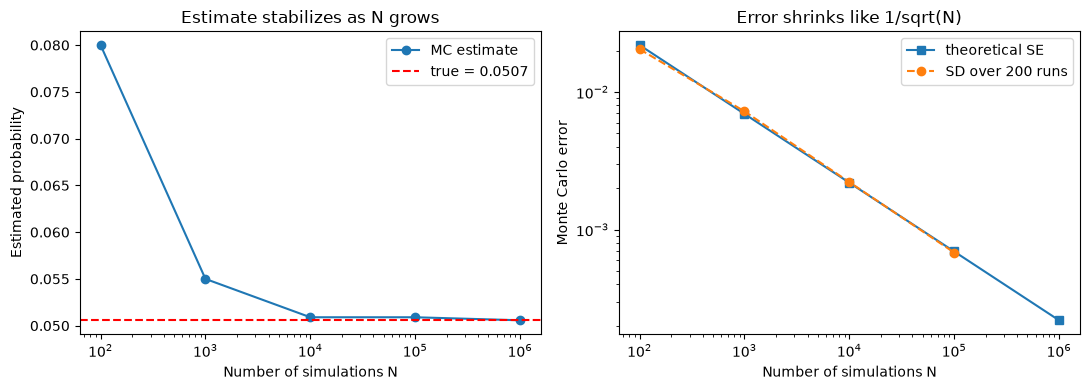

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].semilogx(stability["N"], stability["estimate"], "o-", label="MC estimate")
axes[0].axhline(p_true, color="red", ls="--", label=f"true = {p_true:.4f}")
axes[0].set_xlabel("Number of simulations N")
axes[0].set_ylabel("Estimated probability")
axes[0].set_title("Estimate stabilizes as N grows")
axes[0].legend()

axes[1].loglog(stability["N"], stability["MCSE_theoretical"], "s-", label="theoretical SE")
observed = stability.dropna()
axes[1].loglog(observed["N"], observed["SD_over_200_runs"], "o--", label="SD over 200 runs")
axes[1].set_xlabel("Number of simulations N")
axes[1].set_ylabel("Monte Carlo error")
axes[1].set_title("Error shrinks like 1/sqrt(N)")
axes[1].legend()

plt.tight_layout()
Path("outputs").mkdir(exist_ok=True)
plt.savefig("outputs/mc_stability.png", dpi=150)
plt.show()

**Why more simulations help.** At $N = 100$ the estimate is unreliable: this run gave 0.080 against a true value of 0.0507, and the Monte Carlo SE (about 0.022) is almost half the size of the probability itself. As $N$ grows, the estimates settle near 0.0507. By the law of large numbers, the sample proportion converges to the true probability, and by the central limit theorem its error is roughly normal with a standard error that shrinks like $1/\sqrt N$.

The table and the right panel confirm this: the estimated SE, the theoretical SE, and the SD over 200 repeated runs agree at every size, and the SE falls from about 0.022 at $N = 100$ to about 0.00022 at $N = 1{,}000{,}000$. Each 100-fold increase in $N$ gives only a 10-fold reduction in error, so extra precision gets expensive quickly, and a rare event needs many simulations to be estimated with good relative accuracy. This also supports my choice of $N = 10{,}000$ in Part 1: by that size the estimate is within about 0.0002 of the truth in this run, with an SE around 0.002.

## Part 3 — Bootstrap

**Data.** I use Student's (1908) sleep data: the extra hours of sleep gained by 10 patients under each of two drugs. It is a small real dataset (the same as R's `sleep` data). I write the raw values once to `data/sleep.csv` and from then on only read them from that relative path.

**Statistic.** I use the difference in group means, $\bar x_{\text{drug2}} - \bar x_{\text{drug1}}$. Each bootstrap replicate resamples within each group with replacement, which resamples the observations as units, and then recomputes the statistic. I use $B = 10{,}000$ replicates. The bootstrap SE is the SD of the replicates, and the 95% percentile interval is the middle 95% of them.

In [9]:
Path("data").mkdir(exist_ok=True)
raw = pd.DataFrame({
    "group": ["drug1"] * 10 + ["drug2"] * 10,
    "extra": [0.7, -1.6, -0.2, -1.2, -0.1, 3.4, 3.7, 0.8, 0.0, 2.0,
              1.9, 0.8, 1.1, 0.1, -0.1, 4.4, 5.5, 1.6, 4.6, 3.4],
})
raw.to_csv("data/sleep.csv", index=False)

sleep = pd.read_csv("data/sleep.csv")
drug1 = sleep.loc[sleep["group"] == "drug1", "extra"].to_numpy()
drug2 = sleep.loc[sleep["group"] == "drug2", "extra"].to_numpy()
print(sleep.groupby("group")["extra"].agg(["count", "mean", "std", "median"]).round(3))

       count  mean    std  median
group                            
drug1     10  0.75  1.789    0.35
drug2     10  2.33  2.002    1.75


Observed difference in means : 1.580
Bootstrap SE                 : 0.803
Analytical (Welch) SE        : 0.849
95% percentile CI            : (0.020, 3.170)
Bootstrap mean - observed    : 0.003


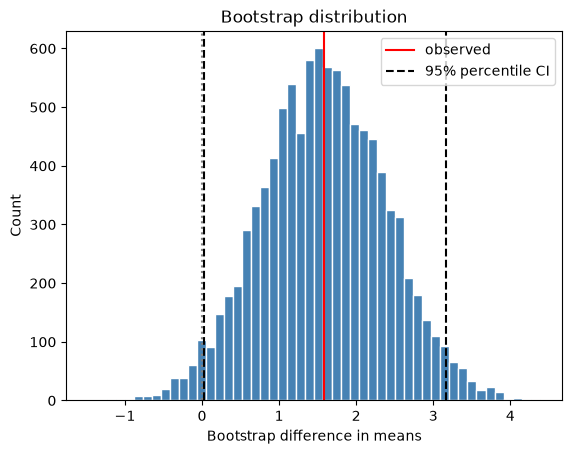

In [10]:
observed_diff = difference_in_means(drug2, drug1)
boot_diffs = bootstrap_two_sample(drug2, drug1, difference_in_means, N_BOOT, rng)

bootstrap_se = boot_diffs.std(ddof=1)
lower, upper = np.quantile(boot_diffs, [0.025, 0.975])
analytical_se = np.sqrt(drug2.var(ddof=1) / len(drug2) + drug1.var(ddof=1) / len(drug1))

print(f"Observed difference in means : {observed_diff:.3f}")
print(f"Bootstrap SE                 : {bootstrap_se:.3f}")
print(f"Analytical (Welch) SE        : {analytical_se:.3f}")
print(f"95% percentile CI            : ({lower:.3f}, {upper:.3f})")
print(f"Bootstrap mean - observed    : {boot_diffs.mean() - observed_diff:.3f}")

plt.hist(boot_diffs, bins=50, color="steelblue", edgecolor="white")
plt.axvline(observed_diff, color="red", label="observed")
plt.axvline(lower, color="black", ls="--", label="95% percentile CI")
plt.axvline(upper, color="black", ls="--")
plt.axvline(0, color="gray", ls=":")
plt.xlabel("Bootstrap difference in means")
plt.ylabel("Count")
plt.title("Bootstrap distribution")
plt.legend()
plt.savefig("outputs/bootstrap_dist.png", dpi=150)
plt.show()

**Checking that $B = 10{,}000$ is enough.** I chose 10,000 replicates because the CI endpoints depend on the tails of the bootstrap distribution, which need many replicates to settle, and with only 20 observations each replicate is very cheap. To check this, I recompute the interval from each half of the replicates and see whether the endpoints move. I also compare my from-scratch result with `scipy.stats.bootstrap`.

In [11]:
half = N_BOOT // 2
print(f"CI from first {half:,} replicates : "
      f"({np.quantile(boot_diffs[:half], 0.025):.3f}, {np.quantile(boot_diffs[:half], 0.975):.3f})")
print(f"CI from last  {half:,} replicates : "
      f"({np.quantile(boot_diffs[half:], 0.025):.3f}, {np.quantile(boot_diffs[half:], 0.975):.3f})")

scipy_boot = stats.bootstrap(
    (drug2, drug1),
    lambda a, b: np.mean(a) - np.mean(b),
    n_resamples=N_BOOT,
    method="percentile",
    vectorized=False,
    rng=rng,
)
print(f"scipy.stats.bootstrap SE : {scipy_boot.standard_error:.3f}")
print(f"scipy.stats.bootstrap CI : ({scipy_boot.confidence_interval.low:.3f}, "
      f"{scipy_boot.confidence_interval.high:.3f})")

CI from first 5,000 replicates : (0.010, 3.160)
CI from last  5,000 replicates : (0.020, 3.180)
scipy.stats.bootstrap SE : 0.818
scipy.stats.bootstrap CI : (-0.030, 3.160)


**Interpretation.** The observed difference is 1.58 extra hours of sleep (drug 2 minus drug 1). The bootstrap SE is about 0.80, close to the analytical Welch SE of about 0.85, and the bootstrap distribution is centered on the observed value (bootstrap mean minus observed is about 0.003), so there is no sign of bias. The 95% percentile interval is roughly (0.02, 3.17). In words: the data are consistent with drug 2 giving anywhere from about zero to about 3.2 more hours of sleep than drug 1.

The lower endpoint sits essentially at zero, so the evidence for a difference is borderline. The check supports the stability of the result: the two halves give similar intervals ((0.01, 3.16) and (0.02, 3.18)), and `scipy.stats.bootstrap` gives a similar SE (about 0.82). Its lower endpoint (about −0.03) falls slightly below zero where mine falls slightly above, but that difference comes from different random resamples and not from an error in either method. With only 10 observations per group, the empirical distribution is a coarse stand-in for the population, so I read the interval as roughly (0, 3.2) rather than as exact endpoints.

## Part 4 — Permutation test

- **Hypotheses.** Let $\mu_1$ and $\mu_2$ be the population mean extra hours of sleep under drug 1 and drug 2.
  - $H_0$: the drug makes no difference, so the extra sleep under drug 1 and drug 2 comes from the same distribution and the group labels are exchangeable. In particular, $\mu_2 - \mu_1 = 0$.
  - $H_A$: the mean extra sleep differs between the two drugs, $\mu_2 - \mu_1 \neq 0$. This is two-sided, so I do not assume in advance which drug gives more sleep.
- **Test statistic.** $T = \bar x_{\text{drug2}} - \bar x_{\text{drug1}}$, with the two-sided p-value based on $|T|$.
- **Null distribution.** I pool all 20 values, randomly reassign 10 to each group (sampling without replacement), recompute $T$, and repeat this $B = 10{,}000$ times. There are $\binom{20}{10} = 184{,}756$ distinct assignments, so 10,000 random permutations approximate the exact null distribution.
- **Monte Carlo p-value with the +1 correction:**
$$\hat p = \frac{1 + \#\{|T^*_b| \ge |T_{\text{obs}}|\}}{B + 1}.$$

**Choosing $B = 10{,}000$.** The p-value is itself a Monte Carlo estimate, with SE $\sqrt{\hat p(1-\hat p)/B}$. At $B = 10{,}000$ and $\hat p$ near 0.08 this SE is about 0.003, small compared with the distance from the usual 0.05 threshold, so the Monte Carlo noise should not change the conclusion. I report that SE below to confirm it.

Observed statistic T_obs : 1.580
Permutations >= |T_obs|  : 801 of 10,000
Monte Carlo p-value (+1) : 0.0802
MC SE of the p-value     : 0.0027
Null mean / SD           : 0.007 / 0.899


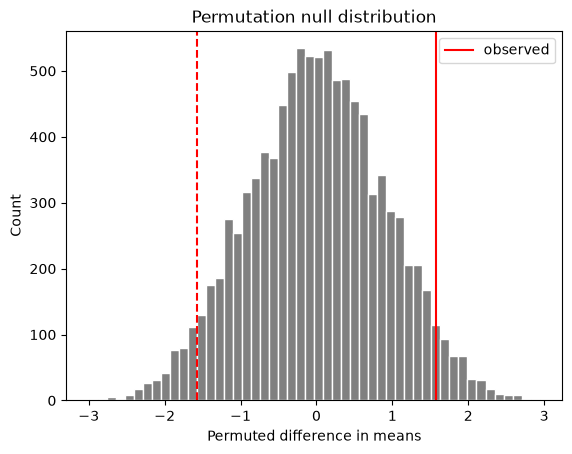

In [12]:
T_obs = difference_in_means(drug2, drug1)
null_dist = permutation_null(drug2, drug1, difference_in_means, N_PERM, rng)

extreme = np.sum(np.abs(null_dist) >= np.abs(T_obs))
p_value = (1 + extreme) / (N_PERM + 1)
p_mcse = np.sqrt(p_value * (1 - p_value) / N_PERM)

print(f"Observed statistic T_obs : {T_obs:.3f}")
print(f"Permutations >= |T_obs|  : {extreme} of {N_PERM:,}")
print(f"Monte Carlo p-value (+1) : {p_value:.4f}")
print(f"MC SE of the p-value     : {p_mcse:.4f}")
print(f"Null mean / SD           : {null_dist.mean():.3f} / {null_dist.std(ddof=1):.3f}")

plt.hist(null_dist, bins=50, color="gray", edgecolor="white")
plt.axvline(T_obs, color="red", label="observed")
plt.axvline(-T_obs, color="red", ls="--")
plt.xlabel("Permuted difference in means")
plt.ylabel("Count")
plt.title("Permutation null distribution")
plt.legend()
plt.savefig("outputs/permutation_null.png", dpi=150)
plt.show()

**Validation.** I compare my p-value with `scipy.stats.permutation_test` and, as a reference, with the Welch t-test.

In [13]:
scipy_perm = stats.permutation_test(
    (drug2, drug1),
    lambda a, b, axis: np.mean(a, axis=axis) - np.mean(b, axis=axis),
    permutation_type="independent",
    alternative="two-sided",
    n_resamples=N_PERM,
    vectorized=True,
    rng=rng,
)
print(f"scipy.stats.permutation_test p-value : {scipy_perm.pvalue:.4f}")
print(f"Welch t-test p-value (reference)     : {stats.ttest_ind(drug2, drug1, equal_var=False).pvalue:.4f}")

scipy.stats.permutation_test p-value : 0.0806
Welch t-test p-value (reference)     : 0.0794


**Interpretation.** The observed difference of 1.58 hours is at least as large in absolute value as 801 of the 10,000 label-shuffled differences, so $\hat p \approx 0.080$. If the two drugs really had the same effect, a difference this large would arise by chance about 8% of the time. At $\alpha = 0.05$ I do not reject $H_0$: the evidence is suggestive but not conclusive. The result matches `scipy.stats.permutation_test` (0.081) and the Welch t-test (0.079).

The Monte Carlo SE of $\hat p$ is about 0.003, so 0.080 is more than ten SEs above 0.05 and the decision does not depend on simulation noise. What limits the conclusion is the small sample (10 per group), not the number of permutations. The null distribution is centered at about zero (mean 0.007) with an SD of about 0.90, as expected under $H_0$.

**Why the permutation distribution is different from the bootstrap distribution.** The code looks similar (repeat, resample, compute the statistic, build an empirical distribution), but the two procedures create different worlds.
- The **permutation distribution** is built under $H_0$. Shuffling the labels forces the two groups to come from the same distribution, by resampling without replacement from the pooled data. It is centered near 0 and answers "how unusual is $T_{\text{obs}}$ if there is no effect?", which gives a p-value.
- The **bootstrap distribution** does not assume $H_0$. It resamples with replacement within each group to mimic repeated sampling from the population. It is centered near the observed statistic (1.58) and answers "how variable is the estimate?", which gives a standard error and a confidence interval.

In short, the permutation distribution is a null distribution used for testing, and the bootstrap distribution is a sampling distribution used for estimation. Both depend on the data I actually observed, so neither can fix an unrepresentative sample.

## Part 5 — Reproducibility

- **Explicit RNG object.** I create `rng = np.random.default_rng(SEED)` once in the setup cell and pass it into every function that uses randomness (`simulate_indicator`, `bootstrap_two_sample`, `permutation_null`, and the SciPy validation calls). I never use the global `np.random.seed`, and I never reset the seed inside a loop.
- **Seed recorded.** The seed is `SEED = 556`. It appears at the top of the notebook and the setup and final cells print it. I also record the simulation sizes (`N_SIM`, `N_BOOT`, `N_PERM`) as named constants and print them.
- **Relative paths only.** Everything I read or write uses relative paths: `data/sleep.csv`, `outputs/*.png`, and `requirements.txt`. I write the raw data once and only read it afterward.
- **Environment.** The notebook needs Python 3.9 or newer and four packages: `numpy`, `pandas`, `matplotlib`, and `scipy`. The final cell records their exact installed versions and writes them to `requirements.txt`, so the environment can be recreated with `python -m pip install -r requirements.txt`.
- **Runs top to bottom.** Every figure and number in the notebook is generated by the code, and I run the notebook after restarting the kernel so that no hidden state is involved.
- **Version control.** I commit the notebook and push it to my repository.

Reproducible does not mean correct. Fixing the seed makes this analysis repeatable, and the validation cells (the Binomial checks and the SciPy comparisons) are what give evidence that it is also right.

In [14]:
import platform
from importlib.metadata import version

print("Seed          :", SEED)
print("RNG           :", type(rng).__name__, "/", rng.bit_generator.__class__.__name__)
print("Python        :", platform.python_version())
print(f"Settings      : N_SIM={N_SIM:,}, N_BOOT={N_BOOT:,}, N_PERM={N_PERM:,}")

packages = ["numpy", "pandas", "matplotlib", "scipy"]
requirements = "\n".join(f"{pkg}=={version(pkg)}" for pkg in packages)
print("\nRequirements (installed versions):")
print(requirements)

Path("requirements.txt").write_text(requirements + "\n")
print("\nFiles written (relative paths):",
      sorted(str(p) for p in Path(".").glob("outputs/*")) + ["data/sleep.csv", "requirements.txt"])

Seed          : 556
RNG           : Generator / PCG64
Python        : 3.14.2
Settings      : N_SIM=10,000, N_BOOT=10,000, N_PERM=10,000

Requirements (installed versions):
numpy==2.5.5
pandas==3.1.1
matplotlib==3.11.2
scipy==1.18.1

Files written (relative paths): ['outputs/bootstrap_dist.png', 'outputs/mc_stability.png', 'outputs/permutation_null.png', 'data/sleep.csv', 'requirements.txt']
